# Normalizing Flows — intuition, mathematics, and PyTorch foundations

> **Notebook goal:** build a solid foundation in probability densities, change of variables, Jacobians, likelihood estimation, and generative-model trade-offs. Each key relationship is checked with small, runnable examples.

A normalizing flow (NF) transforms a simple base distribution, such as a standard Gaussian, into a complex data distribution through invertible maps. Its key advantage is that the model can both **generate** samples and compute their **exact log density**. The trade-off is that transformations must be invertible and their Jacobian determinants must be efficient to evaluate.

**Contents**
1. Densities, likelihood, and change of variables
2. The Jacobian: geometric meaning and computation
3. Composing flows, log-determinants, and numerical stability
4. A minimal 1D flow: training, sampling, and diagnostics
5. When normalizing flows are a good choice


## 1. What are we modeling?

We observe samples $x\in\mathbb R^D$ from an unknown distribution $p_{data}(x)$. A probabilistic model assigns them a density $p_\theta(x)$. Maximum-likelihood training minimizes the negative mean log-likelihood:

$$\mathcal L_{NLL}(\theta)=-\frac1N\sum_{n=1}^N\log p_\theta(x_n).$$

A high density means that the model considers a point likely. Density is not the probability of a point (for continuous variables, the probability of any single point is zero); probabilities refer to regions and are integrals of density.

In a flow, we choose an easy-to-sample base distribution $z\sim p_Z$, usually $\mathcal N(0,I)$, and an invertible transformation $x=f_\theta(z)$. Its inverse is $z=f_\theta^{-1}(x)$. Unlike a GAN, there is no discriminator; unlike a typical VAE, the observation likelihood is computed exactly (apart from any dequantization needed for discrete data).


## 2. Change of variables — where does the determinant come from?

In 1D, a transformation $x=f(z)$ stretches a small interval $dz$ to $dx\approx |f'(z)|dz$. Conservation of probability mass requires $p_X(x)dx=p_Z(z)dz$, so $p_X(x)=p_Z(z)/|f'(z)|$. In multiple dimensions, the local volume scale is the absolute determinant of the Jacobian.

$$\log p_X(x)=\log p_Z(f^{-1}(x))+\log\left|\det\left(\frac{\partial f^{-1}(x)}{\partial x}\right)\right|.$$

Equivalently, for the generative map $x=f(z)$:
$$\log p_X(f(z))=\log p_Z(z)-\log\left|\det\left(\frac{\partial f(z)}{\partial z}\right)\right|.$$

**Sign intuition:** a map that locally stretches space by a factor of 10 dilutes the same probability mass by a factor of 10. The log density therefore changes by $-\log 10$. For a sequence of maps $f_K\circ\dots\circ f_1$, log-determinants add because the determinant of a product of Jacobians is the product of their determinants.


In [1]:
import math
import torch

torch.manual_seed(7)
torch.set_printoptions(precision=4, sci_mode=False)

# x = a*z+b: Gaussian density after an affine transformation.
a, b = 2.0, -0.7
z = torch.tensor([0.0, 1.0, -1.0])
x = a * z + b
log_pz = -0.5 * (z.square() + math.log(2 * math.pi))
log_px_change = log_pz - math.log(abs(a))
log_px_direct = -0.5 * (((x-b)/a).square() + math.log(2*math.pi)) - math.log(abs(a))
print('x:', x)
print('log p(x) via change of variables:', log_px_change)
print('Check against the known distribution:', torch.allclose(log_px_change, log_px_direct))

x: tensor([-0.7000,  1.3000, -2.7000])
log p(x) via change of variables: tensor([-1.6121, -2.1121, -2.1121])
Check against the known distribution: True


## 3. The Jacobian and its computational cost

For $f:\mathbb R^D\to\mathbb R^D$, the Jacobian $J_{ij}=\partial f_i/\partial z_j$ describes local stretching and shearing. Change of variables requires $\log|\det J|$. Naively forming a matrix and computing its determinant generally costs $O(D^3)$, which is impractical for images with thousands of dimensions.

Flow architectures are therefore designed to make the log-determinant cheap: triangular or diagonal transformations, permutations, or specially parameterized matrices. The example below uses autodiff in a small dimension and checks the result against the analytic value.


In [2]:
def f(v):
    # Invertible nonlinear map in 2D: (u,v) -> (u, v + 0.4 sin(u))
    return torch.stack([v[0], v[1] + 0.4 * torch.sin(v[0])])

point = torch.tensor([0.3, -0.2], requires_grad=True)
J = torch.autograd.functional.jacobian(f, point)
sign, logabsdet = torch.linalg.slogdet(J)
print('Jakobian:\n', J.detach())
print('det J =', torch.det(J).item(), '| log|det J| =', logabsdet.item())
print('Expected log|det J| = 0 because the map has diagonal entries (1, 1)')

Jakobian:
 tensor([[1.0000, 0.0000],
        [0.3821, 1.0000]])
det J = 1.0 | log|det J| = 0.0
Expected log|det J| = 0 because the map has diagonal entries (1, 1)


## 4. A flow as a chain of invertible layers

Let $h_0=z$ and $h_k=f_k(h_{k-1})$. Then
$$\log p_X(x)=\log p_Z(h_0)-\sum_{k=1}^K\log|\det J_{f_k}(h_{k-1})|.$$

Every layer needs an inverse (available analytically or efficiently) and a cheap log-determinant. Nonlinear transformations increase expressiveness; permutations or linear transformations alone cannot model complex shapes. A deeper flow can be more expressive, but may require more memory and computation and be harder to optimize.

Real images are discrete. Feeding integer pixel values directly to a continuous model does not correctly describe the probability mass of those values. A common remedy is dequantization: add noise $u\sim U([0,1)^D)$ to pixels and optimize a lower bound on the discrete-image log-likelihood. Our 2D demonstrations avoid this issue.


## 5. A minimal 1D flow: an affine map

We learn $x=\exp(s)z+t$, where $z\sim\mathcal N(0,1)$. Then
$$\log p_X(x)=\log p_Z((x-t)e^{-s})-s.$$

This model has only two degrees of freedom, so it can fit a location and scale but not a multimodal shape. It is useful for checking the likelihood calculation and the full optimization loop.


Training NLL: 2.004 | scale: 1.7944962978363037 | shift: -0.25874653458595276


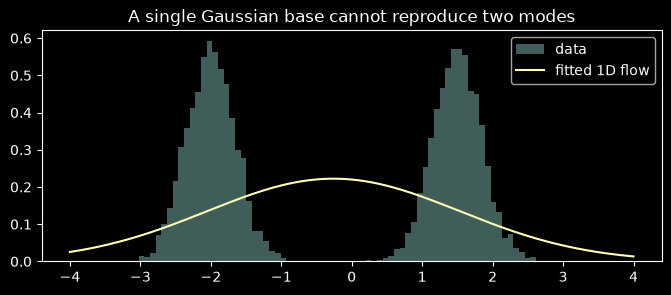

In [3]:
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(11)
# Data with a known non-Gaussian shape: a mixture of two clusters.
n = 6000
component = torch.randint(0, 2, (n,), device=device)
data = torch.randn(n, device=device) * 0.35 + torch.where(component == 0, -2.0, 1.5)

class Affine1D(nn.Module):
    def __init__(self):
        super().__init__(); self.log_scale = nn.Parameter(torch.zeros(())); self.shift = nn.Parameter(torch.zeros(()))
    def log_prob(self, x):
        z = (x - self.shift) * torch.exp(-self.log_scale)
        return -0.5 * (z.square() + math.log(2 * math.pi)) - self.log_scale
    def sample(self, n):
        return torch.randn(n, device=self.shift.device) * torch.exp(self.log_scale) + self.shift

model = Affine1D().to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.04)
for step in range(800):
    batch = data[torch.randint(n, (256,), device=device)]
    loss = -model.log_prob(batch).mean()
    opt.zero_grad(); loss.backward(); opt.step()
print('Training NLL:', round(loss.item(), 3), '| scale:', model.log_scale.exp().item(), '| shift:', model.shift.item())

grid = torch.linspace(-4, 4, 400, device=device)
with torch.no_grad():
    density = model.log_prob(grid).exp().cpu()
plt.figure(figsize=(8, 3)); plt.hist(data.cpu(), bins=70, density=True, alpha=.45, label='data')
plt.plot(grid.cpu(), density, label='fitted 1D flow'); plt.legend(); plt.title('A single Gaussian base cannot reproduce two modes'); plt.show()

## 6. How to diagnose a flow

- **NLL / bits per dimension:** compare the same data, preprocessing, and conventions (including dequantization for images). Lower NLL means higher density assigned to the evaluation set.
- **Samples:** inspect visual quality, but do not treat it as a substitute for likelihood. High density does not always mean semantically attractive images.
- **Numerical invertibility:** check that $f^{-1}(f(z))\approx z$ and that forward and inverse log-determinants cancel.
- **Stability:** monitor scales, NaN/Inf values, and gradients. Limiting log-scale is often necessary.
- **Train vs. validation NLL:** a large gap suggests overfitting; keep validation data out of optimization.

**Strengths:** explicit, exact density; straightforward sampling from the base; and an invertible representation. **Limitations:** computation grows with dimension, Jacobian-friendly architectures impose design trade-offs, perceptual quality may lag behind GANs or diffusion models, and likelihood does not always agree with intuitive semantic quality.

## Summary

The core of a normalizing flow is the change-of-variables equation. We learn an invertible map between a simple distribution and the data; the log density of an observation is the base log density plus a volume correction. Efficient flows use layers that are expressive and invertible while keeping the log-determinant cheap. The next notebook develops this idea with RealNVP.

## Key takeaways

- A flow maps a tractable base distribution to a complex data distribution through invertible transformations.
- The change-of-variables formula corrects density by the absolute Jacobian determinant: $\log p_X(x)=\log p_Z(f^{-1}(x))+\log|\det J_{f^{-1}}(x)|$.
- For a composition of layers, log-determinants add; this makes efficient per-layer determinants essential.
- Flows provide both sampling and exact likelihood, with trade-offs in computational cost and architecture.
- Always check inverse consistency, log-determinant signs, and train/validation likelihood.
